# @ import libraries

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv(r"C:\Users\Soham\Desktop\Fraud Detection System\data\raw\PS_20174392719_1491204439457_log.csv")

In [3]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
df.shape

(6362620, 11)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [6]:
# @ check duplicates values
df.duplicated().sum()

0

In [ ]:
# @ check null values
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [ ]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [ ]:
df = pd.read_csv("C:\\Users\\MY PC\\Downloads\\archive\\PS_20174392719_1491204439457_log.csv")
print(f"Dataset shape: {df.shape}")
print(f"Fraud rate: {df['isFraud'].mean():.4%}")
print(df.head())

sns.set_theme(style="whitegrid")

Dataset shape: (6362620, 11)
Fraud rate: 0.1291%
   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0             0.0        0               0  
1  M2044282225             0.0             0.0        0               0  
2   C553264065             0.0             0.0        1               0  
3    C38997010         21182.0             0.0        1               0  
4  M1230701703             0.0             0.0        0               0  


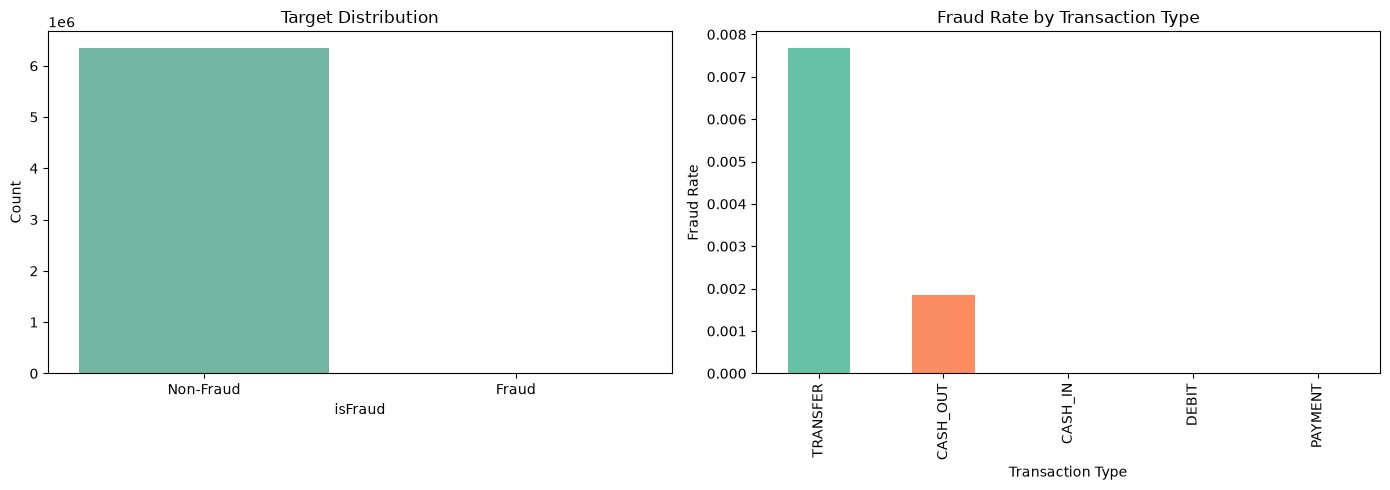

In [ ]:
# Target distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="isFraud", hue="isFraud", dodge=False, ax=axes[0], palette="Set2", legend=False)
axes[0].set_title("Target Distribution")
axes[0].set_xlabel("isFraud")
axes[0].set_ylabel("Count")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Non-Fraud", "Fraud"])

# Fraud rate by transaction type
fraud_by_type = df.groupby("type")["isFraud"].mean().sort_values(ascending=False)
fraud_by_type.plot(kind="bar", ax=axes[1], color=sns.color_palette("Set2", len(fraud_by_type)))
axes[1].set_title("Fraud Rate by Transaction Type")
axes[1].set_xlabel("Transaction Type")
axes[1].set_ylabel("Fraud Rate")
plt.tight_layout()
plt.show()


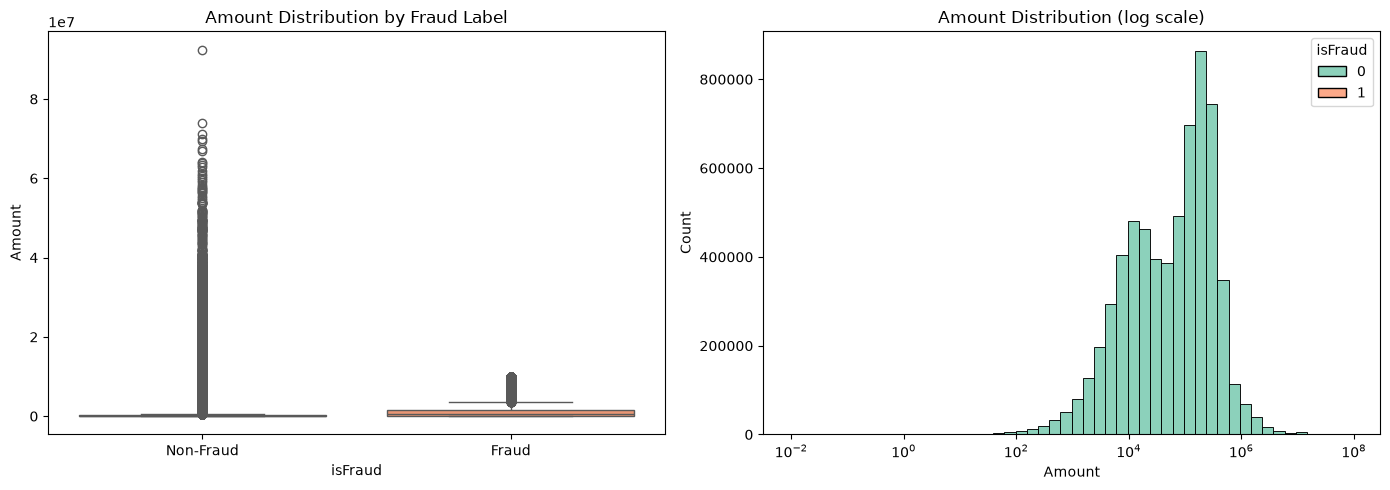

In [ ]:
# Amount distribution by fraud label
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="isFraud", y="amount", hue="isFraud", dodge=False, ax=axes[0], palette="Set2", legend=False)
axes[0].set_title("Amount Distribution by Fraud Label")
axes[0].set_xlabel("isFraud")
axes[0].set_ylabel("Amount")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Non-Fraud", "Fraud"])

sns.histplot(data=df, x="amount", hue="isFraud", bins=50, log_scale=True, multiple="stack", ax=axes[1], palette="Set2")
axes[1].set_title("Amount Distribution (log scale)")
axes[1].set_xlabel("Amount")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

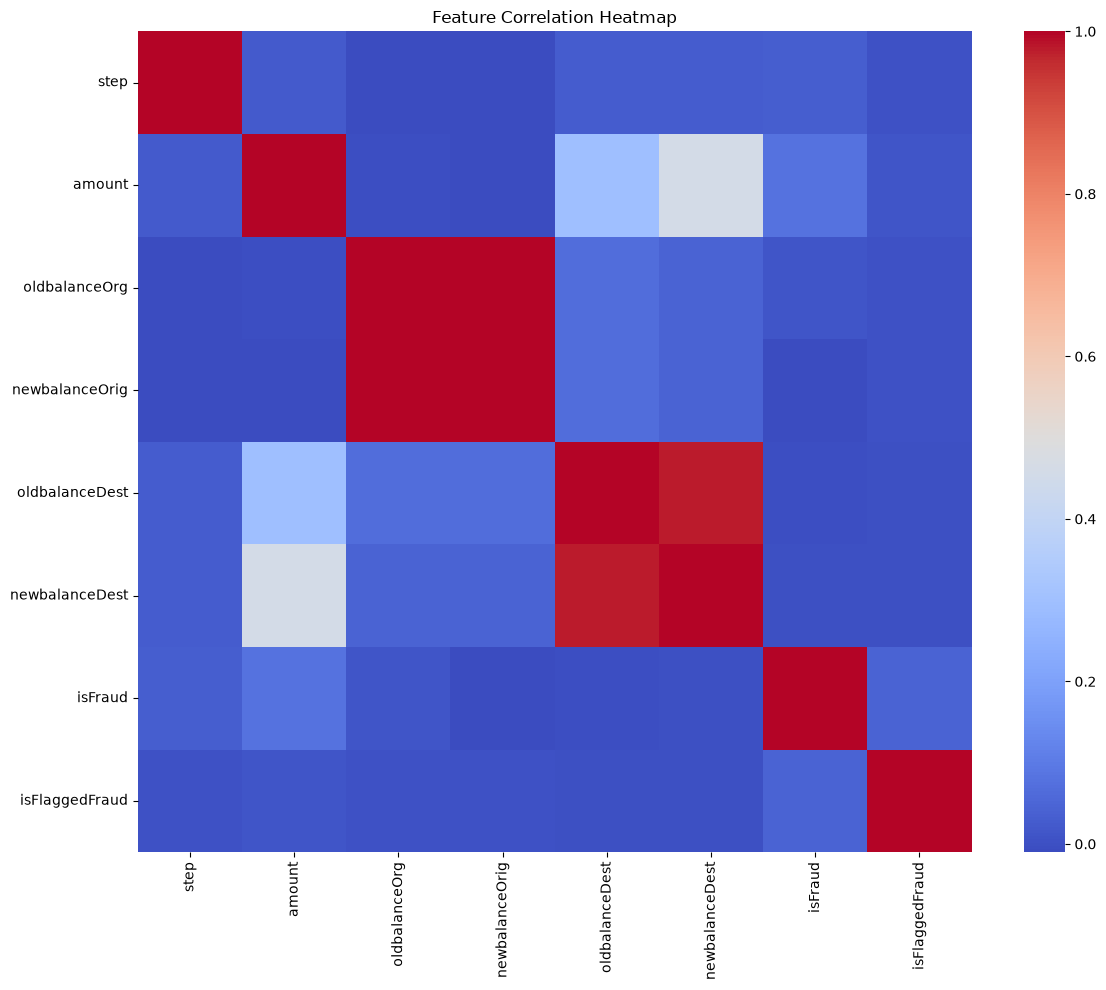

            count       mean          max
type                                     
CASH_IN   1399284  168920.24   1915267.90
CASH_OUT  2237500  176273.96  10000000.00
DEBIT       41432    5483.67    569077.51
PAYMENT   2151495   13057.60    238637.98
TRANSFER   532909  910647.01  92445516.64

Negative/zero amount transactions: 16

Duplicate rows: 0

Missing values:
 step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [ ]:
# Correlation heatmap over numeric features
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[numeric_cols].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=False, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# Quick summary table by transaction type
print(df.groupby("type")["amount"].agg(["count", "mean", "max"]).round(2))
print("\nNegative/zero amount transactions:", (df["amount"] <= 0).sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nMissing values:\n", df.isnull().sum())
